# Predicting loan default at approval time (Lending Club)

This notebook walks through the whole project step by step. Each step calls the same code as the scripts in `src/`, so the notebook and the pipeline always agree.

**Question:** on the day a loan is approved, can we tell which borrowers will not repay?

| Step | What happens | Code |
|---|---|---|
| 1 | Extract: download 2.26M loans from Kaggle | `src/download_data.py` |
| 2 | Transform + load: select, clean, engineer features | `src/etl.py` |
| 3 | EDA with statistical tests | `src/eda.py` |
| 4 | Train 4 models, compare, test the winner on 2015 loans | `src/train.py` |

In [3]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd().parent / "src"))
import config, download_data, etl, eda, train  # noqa: E402

pd.set_option("display.max_columns", 50)
print("Project folder:", config.PROJECT_DIR)

Project folder: /Users/sanketpatil/ml-dl-ai-models-hub/projects/01-lending-club-default


## Step 1: Extract

Downloads the Kaggle dataset (about 1.7 GB) and keeps only the accepted-loans file. If the file is already there, this does nothing, so it's safe to re-run.

In [4]:
download_data.main()

Already downloaded: accepted_2007_to_2018Q4.csv.gz


## Step 2: Transform and load (ETL)

We keep **36-month loans issued 2012 to 2015 that ended as Fully Paid or Charged Off**, so every loan has a final answer. We load **only the columns known on the day of approval**, which avoids data leakage. Then we fix messy values and add credit-analyst features.

Watch how many rows survive each filter in the output below.

In [5]:
etl.main()

Reading accepted_2007_to_2018Q4.csv.gz (about a minute for 2.2M rows)...
Raw rows:                        2,260,701
36-month loans issued 2012-2015: 589,635
... with a final outcome:        589,488
Value fixes: {'dti_invalid': 5, 'income_zero_or_negative': 2, 'revol_util_above_150': 11}
Missing values (share of rows): {'annual_inc': 0.0, 'dti': 0.0, 'revol_util': 0.0005, 'mort_acc': 0.0102, 'emp_years': 0.0599, 'loan_to_income': 0.0, 'installment_to_income': 0.0}
Default rate by year: {2012: 0.1358, 2013: 0.1233, 2014: 0.1373, 2015: 0.1489}
Saved 589,488 rows x 27 columns to data/processed/loans_clean.csv.gz


In [6]:
quality = json.loads((config.REPORTS_DIR / "data_quality.json").read_text())
loans = pd.read_csv(config.CLEAN_FILE)
print(f"{len(loans):,} loans x {loans.shape[1]} columns")
display(loans.head())
pd.Series(quality["missing_share_by_column"], name="share missing").to_frame()

589,488 loans x 27 columns


,issue_year,grade,home_ownership,verification_status,purpose,addr_state,application_type,loan_amnt,int_rate,installment,annual_inc,dti,delinq_2yrs,fico,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,mort_acc,pub_rec_bankruptcies,emp_years,credit_history_years,loan_to_income,installment_to_income,default
0,2015,C,MORTGAGE,Not Verified,debt_consolidation,PA,Individual,3600.0,13.99,123.03,55000.0,5.91,0.0,677.0,1.0,7.0,0.0,2765.0,29.7,13.0,1.0,0.0,10.0,12.334018,0.065455,0.026843,0
1,2015,C,MORTGAGE,Not Verified,small_business,SD,Individual,24700.0,11.99,820.28,65000.0,16.06,1.0,717.0,4.0,22.0,0.0,21470.0,19.2,38.0,4.0,0.0,10.0,16.000000,0.380000,0.151436,0
2,2015,C,RENT,Source Verified,debt_consolidation,GA,Individual,11950.0,13.44,405.18,34000.0,10.20,0.0,692.0,0.0,5.0,0.0,8822.0,68.4,6.0,0.0,0.0,4.0,28.167009,0.351471,0.143005,0
3,2015,B,MORTGAGE,Not Verified,debt_consolidation,MN,Individual,20000.0,9.17,637.58,180000.0,14.67,0.0,682.0,0.0,12.0,0.0,87329.0,84.5,27.0,4.0,0.0,10.0,25.500342,0.111111,0.042505,0
4,2015,B,MORTGAGE,Not Verified,major_purchase,SC,Individual,20000.0,8.49,631.26,85000.0,17.61,1.0,707.0,0.0,8.0,0.0,826.0,5.7,15.0,3.0,0.0,10.0,16.829569,0.235294,0.089119,0


,share missing
annual_inc,0.0000
dti,0.0000
revol_util,0.0005
mort_acc,0.0102
emp_years,0.0599
loan_to_income,0.0000
installment_to_income,0.0000


In [7]:
loans.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
issue_year,589488.0,2014.16,0.96,2012.00,2014.00,2014.00,2015.00,2015.00
loan_amnt,589488.0,12638.48,7819.88,1000.00,7000.00,10000.00,16500.00,35000.00
int_rate,589488.0,12.06,3.88,5.32,8.90,12.05,14.49,28.99
installment,589488.0,419.01,260.56,14.01,226.23,346.69,551.61,1445.46
annual_inc,589486.0,72338.87,47711.42,1200.00,43000.00,60000.00,87600.00,550000.00
dti,589481.0,17.79,8.25,0.00,11.55,17.25,23.60,71.40
delinq_2yrs,589488.0,0.32,0.88,0.00,0.00,0.00,0.00,30.00
fico,589488.0,696.11,30.52,662.00,672.00,687.00,712.00,847.50
inq_last_6mths,589488.0,0.68,0.96,0.00,0.00,0.00,1.00,8.00
open_acc,589488.0,11.36,5.24,0.00,8.00,10.00,14.00,84.00


## Step 3: Exploratory analysis with statistical tests

* **Chi-square + Cramér's V** for categorical features vs default
* **Mann-Whitney U + rank-biserial effect size** for numeric features (skewed data, so no t-test)

With this many rows nearly every p-value is tiny. **Look at the effect sizes** to see which features really matter.

In [8]:
eda.main()

589,488 loans, default rate 14.0%

Categorical features (chi-square):
  grade                p=0          Cramer's V=0.194
  home_ownership       p=0          Cramer's V=0.071
  verification_status  p=0          Cramer's V=0.055
  purpose              p=0          Cramer's V=0.052
  application_type     p=0.0952     Cramer's V=0.002

Numeric features (Mann-Whitney U), sorted by effect size:
  int_rate               median defaulted=13.67      paid=11.67      p=0          effect=0.312
  fico                   median defaulted=682        paid=692        p=0          effect=-0.199
  annual_inc             median defaulted=54400      paid=62000      p=0          effect=-0.153
  dti                    median defaulted=19.23      paid=16.94      p=0          effect=0.134
  loan_to_income         median defaulted=0.2        paid=0.179      p=0          effect=0.107
  inq_last_6mths         median defaulted=1          paid=0          p=0          effect=0.1
  credit_history_years   median defa

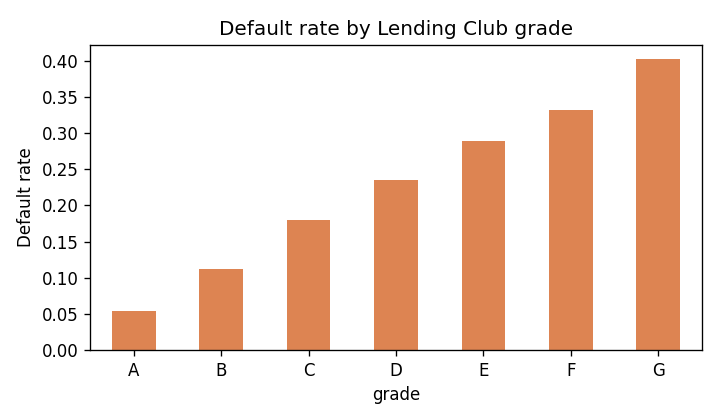

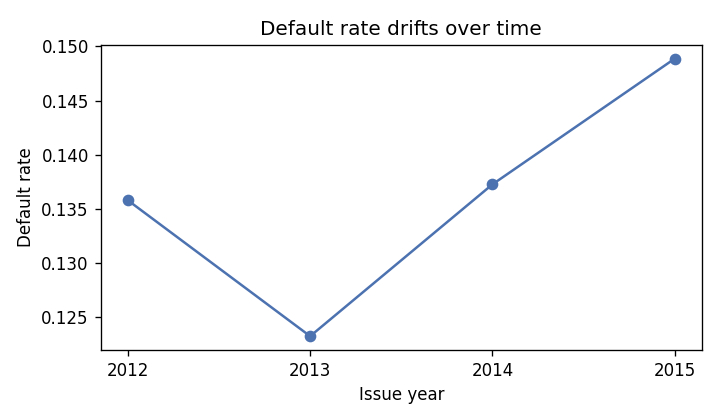

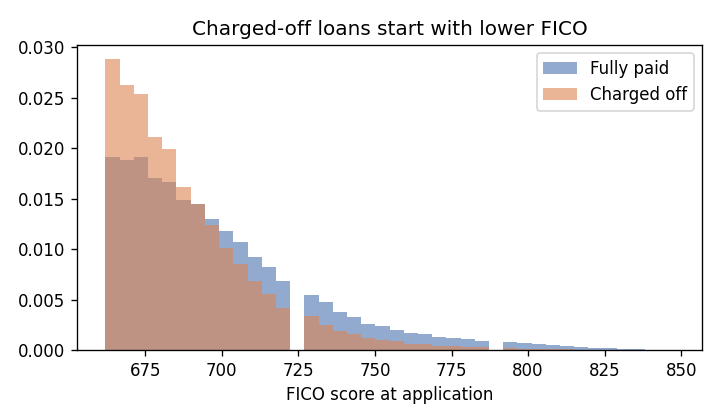

In [9]:
for name in ["default_rate_by_grade", "default_rate_by_year", "fico_by_outcome"]:
    display(Image(filename=str(config.FIGURES_DIR / f"{name}.png")))

## Step 4: Train and compare four models

1. **Out-of-time split:** train on 2012-2014 loans, test on 2015 loans.
2. **Tune** Logistic Regression, Decision Tree, Random Forest and Gradient Boosting with 3-fold cross-validation (ROC AUC).
3. **Compare** them on ROC AUC, PR AUC, F1, precision, recall, accuracy and Brier score.
4. **Choose** the best by CV ROC AUC, pick its F1-maximising threshold, then score the 2015 test set **once**.

This is the slowest step (a few minutes).

In [10]:
train.main()

Train (2012-2014): 306,462 loans, default rate 13.2%
Test  (2015):      283,026 loans, default rate 14.9%
Tuning on a 150,000-loan sample of the training years

logistic_regression  CV ROC AUC 0.6758  best {'C': 0.1}  (2.8s)
decision_tree        CV ROC AUC 0.6578  best {'max_depth': 6, 'min_samples_leaf': 500}  (4.5s)
random_forest        CV ROC AUC 0.6743  best {'max_depth': 16, 'min_samples_leaf': 20}  (29.2s)


ValueError: 
All the 12 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
12 fits failed with the following error:
Traceback (most recent call last):
  File "/Users/sanketpatil/ml-dl-ai-models-hub/.venv/lib/python3.9/site-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/Users/sanketpatil/ml-dl-ai-models-hub/.venv/lib/python3.9/site-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/Users/sanketpatil/ml-dl-ai-models-hub/.venv/lib/python3.9/site-packages/sklearn/pipeline.py", line 662, in fit
    self._final_estimator.fit(Xt, y, **last_step_params["fit"])
  File "/Users/sanketpatil/ml-dl-ai-models-hub/.venv/lib/python3.9/site-packages/sklearn/bas

### Model comparison (cross-validated, training years only)

In [11]:
pd.read_csv(config.REPORTS_DIR / "model_comparison_cv.csv")

FileNotFoundError: [Errno 2] No such file or directory: '/Users/sanketpatil/ml-dl-ai-models-hub/projects/01-lending-club-default/reports/model_comparison_cv.csv'

In [12]:
display(Image(filename=str(config.FIGURES_DIR / "roc_pr_curves.png")))

FileNotFoundError: [Errno 2] No such file or directory: '/Users/sanketpatil/ml-dl-ai-models-hub/projects/01-lending-club-default/reports/figures/roc_pr_curves.png'

### The winner on the 2015 test set

In [ ]:
results = json.loads((config.REPORTS_DIR / "test_results.json").read_text())
print("Winner:", results["winner"], results["winner_params"])
pd.DataFrame({"threshold 0.5": results["test_metrics_threshold_0.5"],
              "tuned threshold": results["test_metrics_tuned_threshold"]})

In [ ]:
display(Image(filename=str(config.FIGURES_DIR / "confusion_matrices.png")))
display(Image(filename=str(config.FIGURES_DIR / "feature_importance.png")))

### Business view: risk deciles

Loans are sorted from riskiest to safest and cut into 10 groups. `cumulative_defaults_caught` shows how many of all defaults sit in the riskiest X% of loans. Compare `predicted_pd` with `actual_default_rate` to check whether the probabilities are calibrated.

In [ ]:
display(Image(filename=str(config.FIGURES_DIR / "risk_deciles.png")))
pd.read_csv(config.REPORTS_DIR / "test_risk_deciles.csv")

## Conclusion

_Write 3-4 sentences here after the run: which model won and by how much, what the riskiest 10-20% of loans contain, and the top features. The same summary goes into the README._